# 질문 재작성과 검색

**이 노트북에서 할 일**

1. 대화에서 대상이 빠진 후속 질문 다섯 개를 준비합니다.
2. 대화 기록과 후속 질문을 모델에 넣어 독립 질문을 만듭니다.
3. 대상 있는 질문·대상 빠진 질문·재작성문·합친 순위를 같은 지표로 견줍니다.
4. 대화 기록 자리를 「없음」으로 바꿔 다시 재작성하고 표에 한 줄을 더합니다.

**준비물** — 프로젝트 폴더의 `.env`에 `OPENAI_API_KEY`가 있어야 합니다.
답을 쓰는 모델 요청은 재작성 다섯 번과 값 바꿔 보기 다섯 번으로 모두 열 번입니다.
임베딩 요청은 문서 청크 1번과 질문 20번으로 모두 스물한 번입니다.
예상 비용은 미화 0.01달러 아래이고 실행 시간은 1분 안팎입니다.
이 챕터에서 답을 쓰는 모델을 부르는 첫 절입니다.

**데이터** — 두 파일 모두 실습 묶음에 들어 있습니다.

- 문서 `labs/part3/ch12-retrieval-tuning/data/advanced-documents.json`(부모 6건·문서 청크 175개)
- 질문 `labs/part3/ch12-retrieval-tuning/data/advanced-queries.json`(30개)

**강의와 실습 범위** — 강의 시간에는 6~10절을 읽습니다.
대화 자료를 만드는 자리가 6절이고 재작성 함수를 만드는 자리가 7절입니다.
9절이 한 대화의 결과이고 10절이 대화 다섯 개의 평균입니다.
1~5절은 함께 실행하고 11절은 실습 시간에 다시 읽습니다.

**기준 버전** — 첫 셀에서 다섯 패키지를 고정한 판으로 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch12-retrieval-tuning`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

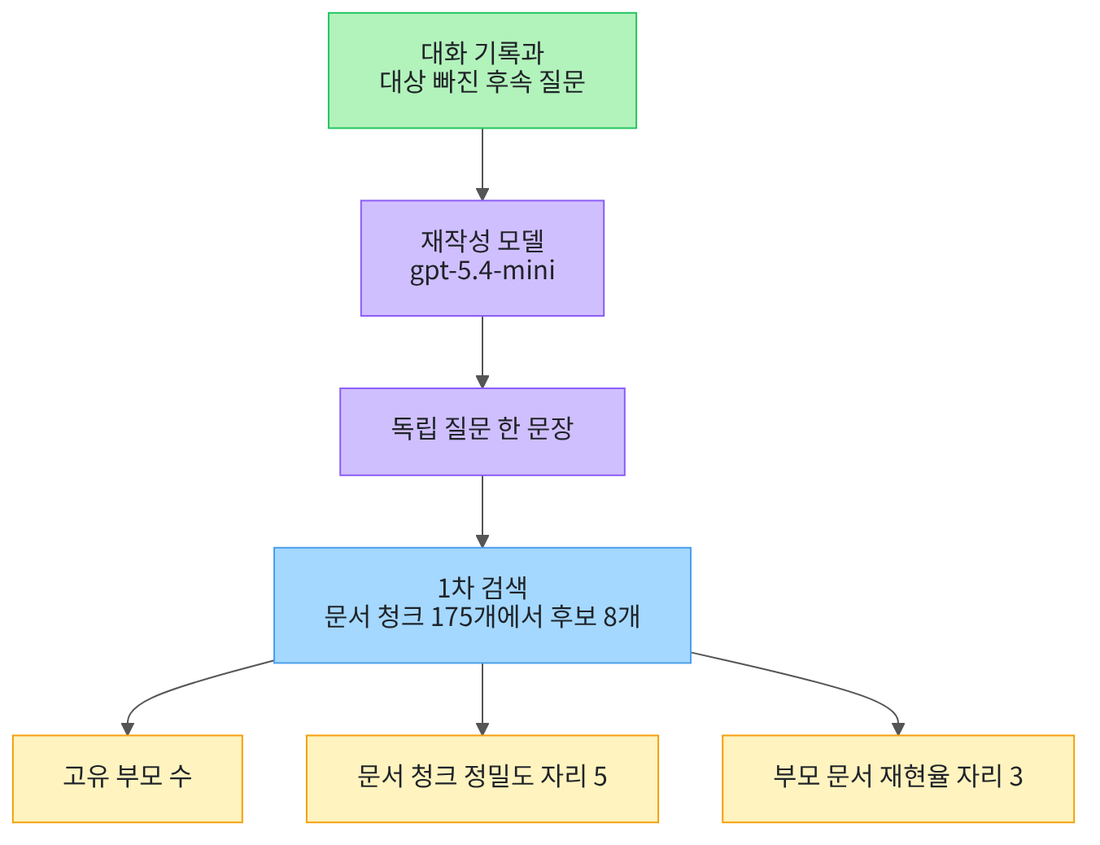

맨 위 초록 상자가 학생이 적어 넣는 대화 기록과 후속 질문입니다.
그 아래 보라 상자가 이 절이 새로 부르는 재작성 모델입니다.
모델이 낸 독립 질문 한 문장이 그다음 보라 상자입니다.
파란 상자에서 07~10절과 같은 방법으로 후보 여덟 개를 만듭니다.
맨 아래 노란 상자 세 개가 보고 자리 다섯 개에서 재는 값입니다.

## 1. 준비

첫 셀은 패키지 다섯 개를 설치하고 설치된 버전을 출력합니다.
10절 네 개에 답을 쓰는 모델을 부르는 꾸러미 하나를 더했습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3" "kiwipiepy==0.23.2" "rank-bm25==0.2.2"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("kiwipiepy:", version("kiwipiepy"))
print("rank-bm25:", version("rank-bm25"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3
kiwipiepy: 0.23.2
rank-bm25: 0.2.2


**결과 읽기** — 설치가 끝나면 `langchain: 1.4.0`과 `rank-bm25: 0.2.2`가 보입니다.
다섯 줄이 모두 보이면 다음 셀로 넘어갑니다.

다음 셀은 이 절에서 쓸 이름 여섯 개를 불러옵니다.

In [2]:
# 자료 읽기·제곱근·형태소 분석·모델 준비·임베딩·낱말 점수에 쓸 이름을 불러옵니다
import json
import math
import os

from kiwipiepy import Kiwi
from langchain.chat_models import init_chat_model
from langchain_openai import OpenAIEmbeddings
from rank_bm25 import BM25Okapi

print("불러온 이름:", "json", "math", "Kiwi", "init_chat_model", "OpenAIEmbeddings", "BM25Okapi")

불러온 이름: json math Kiwi init_chat_model OpenAIEmbeddings BM25Okapi


**결과 읽기** — 출력 줄은 `불러온 이름:` 뒤에 이름 여섯 개가 붙은 한 줄입니다.
이름 `init_chat_model`이 07~10절에는 없던 것입니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 문장을 고르게 합니다.
설정 `reasoning_effort="none"`은 답을 쓰기 전에 따로 생각하는 단계를 두지 않게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-18에 이 모델로 실행한 결과입니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~10절과 같은 코드입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.

다음 셀은 07~10절과 같은 자료 두 벌을 읽습니다.

In [6]:
# 07~10절과 같은 파일 두 벌을 읽습니다
data_path = root_path + "/labs/part3/ch12-retrieval-tuning/data"
with open(data_path + "/advanced-documents.json", encoding="utf-8") as file:
    documents = json.loads(file.read())
with open(data_path + "/advanced-queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
parents = documents["parents"]
chunks = documents["chunks"]
print("부모 문서 수:", len(parents))
print("문서 청크 수:", len(chunks))
print("질문 수:", len(queries))

부모 문서 수: 6
문서 청크 수: 175
질문 수: 30


**결과 읽기** — `부모 문서 수: 6`과 `문서 청크 수: 175`, `질문 수: 30`이 보입니다.
07~10절과 같은 파일이라 세 값도 같습니다.

## 2. 이 절에서 쓸 값 정하기

01~10절에서 쓴 값을 그대로 다시 정합니다.
이 절은 순위 목록을 네 개까지 합치므로 가중치 목록도 네 개짜리를 하나 더 만듭니다.

In [7]:
# 01~10절에서 쓴 값을 그대로 다시 정하고 네 목록을 합칠 때 쓸 가중치를 더합니다
similarity_top = 1
keep_tags = ["NNG", "NNP", "NNB", "NR", "VV", "VA", "MAG", "SN", "SL"]
rank_constant = 60
equal_weights = [1.0, 1.0]
four_weights = [1.0, 1.0, 1.0, 1.0]
candidate_count = 8
recall_place = 3
report_place = 5
print("코사인 유사도의 가장 큰 값:", similarity_top, "| 남길 품사 표시 수:", len(keep_tags))
print("순위 상수:", rank_constant, "| 같은 가중치:", equal_weights)
print("네 순위 목록에 줄 가중치:", four_weights)
print("후보 수:", candidate_count)
print("부모 문서 재현율을 재는 자리:", recall_place, "| 보고 자리:", report_place)

코사인 유사도의 가장 큰 값: 1 | 남길 품사 표시 수: 9
순위 상수: 60 | 같은 가중치: [1.0, 1.0]
네 순위 목록에 줄 가중치: [1.0, 1.0, 1.0, 1.0]
후보 수: 8
부모 문서 재현율을 재는 자리: 3 | 보고 자리: 5


**결과 읽기** — 줄 `순위 상수: 60 | 같은 가중치: [1.0, 1.0]`은 06~10절과 같은 값입니다.
줄 `네 순위 목록에 줄 가중치: [1.0, 1.0, 1.0, 1.0]`이 이 절에서 더한 값입니다.
줄 `후보 수: 8`과 `부모 문서 재현율을 재는 자리: 3 | 보고 자리: 5`도 08~10절과 같습니다.

## 3. 검색에 쓸 재료 만들기

문서 청크마다 제목과 본문을 이어 붙여 글 하나로 만듭니다.
청크 ID로 부모 문서 ID를 찾을 수 있게 짝도 함께 만들어 둡니다.

In [8]:
# 문서 청크마다 제목과 본문을 이어 붙이고 청크 ID·부모 문서 ID를 짝지어 둡니다
chunk_texts = []
chunk_ids = []
parent_by_chunk = {}
for chunk in chunks:
    chunk_text = chunk["title"] + " " + chunk["text"]
    chunk_texts.append(chunk_text)
    chunk_ids.append(chunk["chunk_id"])
    parent_by_chunk[chunk["chunk_id"]] = chunk["parent_id"]
all_chunk_count = len(chunk_ids)
print("이어 붙인 글 수:", len(chunk_texts))
print("첫 문서 청크 ID:", chunk_ids[0])

이어 붙인 글 수: 175
첫 문서 청크 ID: E01-P01-C01


**결과 읽기** — `이어 붙인 글 수: 175`가 보입니다.
줄 `첫 문서 청크 ID: E01-P01-C01`의 이름 앞머리가 그 문서 청크의 부모 문서 ID입니다.

다음 셀은 문서 청크를 벡터로 바꿉니다. 01~10절과 같은 모델을 씁니다.
질문 쪽 벡터는 질문마다 문장이 달라 뒤에서 따로 만듭니다.

In [9]:
# 01~10절과 같은 모델로 문서 청크를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
chunk_vectors = embedding_model.embed_documents(chunk_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 청크 벡터 수:", len(chunk_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 청크 벡터 수: 175


**결과 읽기** — `벡터의 숫자 개수 설정: 256`과 `문서 청크 벡터 수: 175`가 보입니다.
여기까지 임베딩 요청은 한 번입니다.

## 4. 앞 절에서 만든 함수 다시 만들기

다음 아홉 셀은 01~10절에서 만든 함수 열네 개를 같은 코드로 다시 정의합니다.
셀마다 첫 줄 주석에 어느 절 함수인지 적었습니다.
앞 절에서 이미 읽은 코드라 셀 하나에 함수를 둘이나 셋씩 담았습니다.
모두 정의 셀이라 출력이 없습니다.

In [10]:
# 답할 수 있고 정답 부모 문서 ID가 있는 질문만 남깁니다(08~10절과 같은 코드)
def eligible_items(subset):
    picked = []
    for item in subset:
        gold_ids = []
        # 같은 정답 ID가 두 번 적혀 있으면 지표의 나누는 수가 달라져 한 번만 둡니다
        for gold_id in item["gold_doc_ids"]:
            if gold_id not in gold_ids:
                gold_ids.append(gold_id)
        item["gold_doc_ids"] = gold_ids
        if item["answerable"] and len(gold_ids) > 0:
            picked.append(item)
    return picked

In [11]:
# 01절 점곱·길이·코사인 유사도 함수를 같은 코드로 다시 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total


def vector_length(vector):
    squared_sum = dot_product(vector, vector)
    return math.sqrt(squared_sum)


def cosine_similarity(first, second):
    dot = dot_product(first, second)
    length_product = vector_length(first) * vector_length(second)
    return dot / length_product

In [12]:
# 01절 코사인 거리와 04~10절 형태소 고르기를 같은 코드로 다시 정의합니다
def cosine_distance(first, second):
    similarity = cosine_similarity(first, second)
    return similarity_top - similarity


kiwi = Kiwi()


def kiwi_terms(text):
    terms = []
    for token in kiwi.tokenize(text):
        # 조사와 어미는 품사 표시가 목록에 없어 빠집니다
        if token.tag in keep_tags:
            terms.append(token.form)
    return terms

In [13]:
# 05~10절과 같은 코드로 거리가 작은 순서의 순위 목록을 만듭니다
def rank_by_distance(question_vector, top_count):
    pairs = []
    for i in range(len(chunk_ids)):
        distance = cosine_distance(question_vector, chunk_vectors[i])
        pairs.append((distance, chunk_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"chunk_id": pair[1], "거리": round(pair[0], 2)})
    return hit_list[:top_count]

In [14]:
# 05~10절과 같은 코드로 낱말 겹침 점수가 큰 순서의 순위 목록을 만듭니다
def rank_by_bm25(question, top_count):
    question_terms = kiwi_terms(question)
    scores = bm25_model.get_scores(question_terms)
    pairs = []
    for i in range(len(chunk_ids)):
        # 점수에 음수를 붙이면 sorted가 큰 점수를 앞으로 보냅니다
        pairs.append((0 - scores[i], chunk_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"chunk_id": pair[1], "점수": round(0 - pair[0], 2)})
    return hit_list[:top_count]

In [15]:
# 07~10절 문서 청크 ID 모으기와 부모 문서 ID로 바꾸기를 같은 코드로 다시 정의합니다
def unique_chunk_ids(hit_list):
    found_ids = []
    for hit in hit_list:
        if hit["chunk_id"] not in found_ids:
            found_ids.append(hit["chunk_id"])
    return found_ids


def parent_ids_of(found_chunk_ids):
    parent_ids = []
    for chunk_id in found_chunk_ids:
        parent_id = parent_by_chunk[chunk_id]
        # 여러 문서 청크가 같은 부모를 가리키면 처음 나온 자리만 남깁니다
        if parent_id not in parent_ids:
            parent_ids.append(parent_id)
    return parent_ids

In [16]:
# 06~10절과 같은 코드로 순위 목록 여러 개의 자리 몫을 더합니다
def fuse_scores(ranking_list, weight_list):
    scores = {}
    for list_index in range(len(ranking_list)):
        ranking = ranking_list[list_index]
        weight = weight_list[list_index]
        # 자리 번호는 1부터 세고 앞자리일수록 나누는 수가 작아 몫이 큽니다
        for position in range(len(ranking)):
            chunk_id = ranking[position]
            share = weight / (rank_constant + position + 1)
            scores[chunk_id] = scores.get(chunk_id, 0.0) + share
    return scores

In [17]:
# 06~10절과 같은 코드로 합친 점수가 큰 순서의 문서 청크 ID 목록을 만듭니다
def fuse_rank(ranking_list, weight_list):
    scores = fuse_scores(ranking_list, weight_list)
    pairs = []
    for chunk_id in scores:
        pairs.append((0 - scores[chunk_id], chunk_id))
    fused_ids = []
    for pair in sorted(pairs):
        fused_ids.append(pair[1])
    return fused_ids

In [18]:
# Ch 11 02절 재현율과 08~10절 문서 청크 정밀도를 같은 코드로 다시 정의합니다
def recall_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / len(gold_doc_ids)


def chunk_precision_at(found_chunk_ids, gold_doc_ids, cutoff):
    top_ids = found_chunk_ids[:cutoff]
    found_count = 0
    for chunk_id in top_ids:
        if parent_by_chunk[chunk_id] in gold_doc_ids:
            found_count = found_count + 1
    return found_count / cutoff

## 5. 개발 묶음과 후보 만들기

Ch 11이 정한 약속은 개발 15문항으로 설정을 고르는 것입니다.
시험 15문항은 설정을 다 고른 뒤 12절에서 한 번만 씁니다.
다음 셀이 개발 묶음을 가립니다.

In [19]:
# 질문 30개에서 개발 묶음만 고르고 답할 수 있는 질문만 남깁니다
dev_all = []
for query in queries:
    if query["split"] == "dev":
        dev_all.append(query)
dev_queries = eligible_items(dev_all)
print("개발 질문 수:", len(dev_queries))
print("시험 질문 수:", len(queries) - len(dev_all))
print("첫 개발 질문:", dev_queries[0]["qid"], "|", dev_queries[0]["question"])
print("그 질문의 정답 부모 문서 ID:", dev_queries[0]["gold_doc_ids"])

개발 질문 수: 15
시험 질문 수: 15
첫 개발 질문: Q001 | 미르시립도서관의 정기 휴관일은 언제인가요?
그 질문의 정답 부모 문서 ID: ['E01']


**결과 읽기** — `개발 질문 수: 15`와 `시험 질문 수: 15`가 보입니다.
줄 `첫 개발 질문:` 뒤에 질문 ID와 질문 글이 있습니다.
줄 `그 질문의 정답 부모 문서 ID: ['E01']`의 값이 부모 문서 ID 목록입니다.

다음 셀은 문서 청크의 검색 낱말 목록으로 BM25 모델을 만듭니다.

In [20]:
# 문서 청크마다 검색 낱말 목록을 만들고 그 목록으로 BM25 모델을 만듭니다(04~10절과 같은 코드)
kiwi_corpus = []
for text in chunk_texts:
    kiwi_corpus.append(kiwi_terms(text))
bm25_model = BM25Okapi(kiwi_corpus)
print("검색 낱말 목록 수:", len(kiwi_corpus))
print("BM25 모델이 본 문서 청크 수:", bm25_model.corpus_size)
print("문서 청크 하나의 평균 검색 낱말 수:", round(bm25_model.avgdl, 2))

검색 낱말 목록 수: 175
BM25 모델이 본 문서 청크 수: 175
문서 청크 하나의 평균 검색 낱말 수: 44.01


**결과 읽기** — `검색 낱말 목록 수: 175`와 `BM25 모델이 본 문서 청크 수: 175`가 보입니다.
줄 `문서 청크 하나의 평균 검색 낱말 수: 44.01`은 07~10절과 같은 값입니다.

다음 셀은 질문 하나를 후보 목록으로 바꾸는 함수 둘입니다.
07~10절은 개발 질문 열다섯 개를 한 번에 벡터로 바꿨습니다.
이 절은 같은 질문을 여러 모양으로 바꿔 검색하므로 질문마다 따로 부릅니다.

In [21]:
# 질문 하나로 순위 목록 두 개를 만들고 합친 차례의 앞자리를 후보로 자릅니다
def ranking_lists(question):
    question_vector = embedding_model.embed_query(question)
    distance_hits = rank_by_distance(question_vector, all_chunk_count)
    score_hits = rank_by_bm25(question, all_chunk_count)
    return [unique_chunk_ids(distance_hits), unique_chunk_ids(score_hits)]


def candidates_of(ranking_list, weight_list):
    fused_ids = fuse_rank(ranking_list, weight_list)
    return fused_ids[:candidate_count]


# 보고 자리 다섯 개에서 고유 부모 수·정밀도·재현율 세 값을 냅니다
def measure(found_chunk_ids, gold_doc_ids):
    top_ids = found_chunk_ids[:report_place]
    parent_ids = parent_ids_of(top_ids)
    precision = chunk_precision_at(found_chunk_ids, gold_doc_ids, report_place)
    recall = recall_at(parent_ids, gold_doc_ids, recall_place)
    return len(parent_ids), round(precision, 2), round(recall, 2)

정의 셀이라 출력이 없습니다.
첫 함수는 벡터 거리 순위와 낱말 겹침 순위 두 개를 목록에 담아 냅니다.
둘째 함수는 그 목록들을 06절 방법으로 합쳐 앞자리 여덟 개를 자릅니다.
목록을 네 개 넣으면 가중치도 네 개를 넣어야 합니다.

셋째 함수는 후보 목록 하나에서 값 세 개를 냅니다.
고유 부모 수는 보고 자리 다섯 개의 부모를 중복 없이 센 수입니다.
10절에서는 이 값을 다양성으로 읽었고 이 절에서는 후보가 몇 문서로 흩어졌는지로 읽습니다.
문서 청크 정밀도와 부모 문서 재현율은 08·09절 함수를 그대로 부릅니다.

## 6. 대화 자료 만들기

대화의 후속 질문에는 앞에서 말한 대상이 빠지기 쉽습니다.
다음 셀은 개발 질문 다섯 개를 골라 대화 기록과 대상이 빠진 질문으로 나눈 것입니다.

In [22]:
# 대화 다섯 개를 적습니다: 한 줄은 (질문 ID, 대화 기록, 대상이 빠진 후속 질문)입니다
conversation_rows = [
    ("Q001", "미르시립도서관 이용 안내를 보고 있어요.", "그곳의 정기 휴관일은 언제인가요?"),
    ("Q005", "미르시립도서관 열람실을 쓰려고 해요.", "그곳 좌석을 예약하고 입실하지 않으면 몇 분 뒤 취소되나요?"),
    ("Q041", "도우미봇 R2 기술 사양서를 보고 있어요.", "그 로봇 로컬 API 토큰의 유효 기간은?"),
    ("Q085", "누리테크와 맺은 부품 공급 기본계약서를 검토하고 있어요.", "납기를 지체하면 지체상금은 얼마이며 한도는?"),
    ("Q087", "누리테크와 맺은 부품 공급 기본계약서를 검토하고 있어요.", "그 모듈의 2026년 2월 이후 단가와 2025년 단가는?"),
]
print("대화 수:", len(conversation_rows))
print("첫 대화 기록:", conversation_rows[0][1])

대화 수: 5
첫 대화 기록: 미르시립도서관 이용 안내를 보고 있어요.


**결과 읽기** — `대화 수: 5`가 보입니다.
줄 `첫 대화 기록: 미르시립도서관 이용 안내를 보고 있어요.`가 첫 대화의 앞 문장입니다.

다음 셀은 질문 ID로 대상 있는 질문과 정답 부모를 찾을 수 있게 짝지어 둡니다.

In [23]:
# 질문 ID로 대상 있는 질문과 정답 부모 문서 ID를 찾을 수 있게 짝지어 둡니다
question_by_id = {}
gold_by_id = {}
for item in dev_queries:
    question_by_id[item["qid"]] = item["question"]
    gold_by_id[item["qid"]] = item["gold_doc_ids"]
print("질문 ID | 정답 부모 | 대상 있는 질문 | 대상 빠진 질문")
for row in conversation_rows:
    print(row[0], "|", gold_by_id[row[0]], "|", question_by_id[row[0]], "|", row[2])

질문 ID | 정답 부모 | 대상 있는 질문 | 대상 빠진 질문
Q001 | ['E01'] | 미르시립도서관의 정기 휴관일은 언제인가요? | 그곳의 정기 휴관일은 언제인가요?
Q005 | ['E01'] | 열람실 좌석을 예약하고 입실하지 않으면 몇 분 뒤 취소되나요? | 그곳 좌석을 예약하고 입실하지 않으면 몇 분 뒤 취소되나요?
Q041 | ['M01'] | R2 로컬 API 토큰의 유효 기간은? | 그 로봇 로컬 API 토큰의 유효 기간은?
Q085 | ['H01'] | 누리테크가 납기를 지체하면 지체상금은 얼마이며 한도는? | 납기를 지체하면 지체상금은 얼마이며 한도는?
Q087 | ['H01'] | NT-LD-16 라이다 모듈의 2026년 2월 이후 단가와 2025년 단가는? | 그 모듈의 2026년 2월 이후 단가와 2025년 단가는?


**결과 읽기** — 라벨 줄 아래 다섯 줄이 나옵니다.
줄 `Q001`을 보면 대상 있는 질문에는 `미르시립도서관`이 있고 대상 빠진 질문에는 `그곳`만 있습니다.
정답 부모 칸은 `['E01']`처럼 목록입니다.

## 7. 질문을 다시 쓰는 함수

질문 재작성은 대화 기록을 함께 보고 빠진 대상을 채운 한 문장을 만드는 일입니다.
다음 셀은 프롬프트를 만들어 모델을 한 번 부르는 함수입니다.

In [24]:
# 대화 기록과 후속 질문을 넣어 독립 질문 한 문장을 받습니다(모델 요청 1번)
def rewrite_question(history_text, question):
    prompt = "다음 대화의 마지막 질문을 문서 검색에 쓸 독립 질문 한 문장으로 다시 쓰세요.\n"
    prompt = prompt + "설명이나 따옴표를 붙이지 마세요.\n"
    prompt = prompt + "대화 기록: " + history_text + "\n"
    prompt = prompt + "마지막 질문: " + question
    answer = model.invoke(prompt)
    return answer.text.strip()

정의 셀이라 출력이 없습니다.
프롬프트는 네 줄이고 대화 기록과 마지막 질문을 각각 한 줄에 담습니다.
줄 `answer.text`는 모델이 쓴 글이고 앞뒤 공백을 떼어 냅니다.
모델이 쓴 문장은 실행마다 달라질 수 있으므로 `assert`로 낱말을 확인하지 않습니다.

다음 셀이 대화 다섯 개를 차례로 재작성합니다.
반복문 안에서는 담기만 하고 다 끝난 뒤 한꺼번에 출력합니다.

In [25]:
# 대화 다섯 개를 차례로 재작성하고 다 끝난 뒤 한꺼번에 출력합니다(모델 요청 5번)
rewritten_by_id = {}
for row in conversation_rows:
    rewritten_by_id[row[0]] = rewrite_question(row[1], row[2])
print("만든 재작성문 수:", len(rewritten_by_id))
print("질문 ID | 재작성문")
for row in conversation_rows:
    print(row[0], "|", rewritten_by_id[row[0]])
assert len(rewritten_by_id) == len(conversation_rows), "대화마다 재작성문이 하나씩 있어야 합니다."

만든 재작성문 수: 5
질문 ID | 재작성문
Q001 | 미르시립도서관의 정기 휴관일은 언제인가요?
Q005 | 미르시립도서관 열람실 좌석을 예약한 뒤 입실하지 않으면 몇 분 후에 예약이 취소되나요?
Q041 | 도우미봇 R2 로컬 API 토큰의 유효 기간은 얼마인가?
Q085 | 납기 지체 시 지체상금의 금액과 한도는 어떻게 되나요?
Q087 | 그 모듈의 2025년 단가와 2026년 2월 이후 단가는 얼마인가?


**결과 읽기** — `만든 재작성문 수: 5`가 보이고 라벨 줄 아래 다섯 줄이 나옵니다.
줄 `Q001`의 재작성문에는 대화 기록에 있던 `미르시립도서관`이 들어왔습니다.
줄 `Q087`처럼 대상이 채워지지 않은 줄도 있습니다.

확인 줄 `assert`는 재작성문 개수만 봅니다. 문장 속 낱말은 확인하지 않습니다.
같은 설정으로 다시 실행해도 문장은 조금 달라질 수 있습니다.

## 8. 갈래 네 가지의 후보 목록

이제 견줄 갈래를 정합니다.
대상 있는 질문은 대화 없이도 검색할 수 있는 원래 개발 질문입니다.
대상 빠진 질문은 대화의 후속 질문 그대로이고 재작성문은 모델이 쓴 문장입니다.
합친 순위는 대상 빠진 질문과 재작성문의 순위 목록 네 개를 06절 방법으로 합친 것입니다.

다음 셀은 대화마다 갈래 네 가지의 후보 목록을 만듭니다.
질문 세 가지를 각각 벡터로 바꾸므로 임베딩 요청이 열다섯 번 늘어납니다.

In [26]:
# 갈래 네 가지를 정하고 대화 다섯 개마다 후보 목록을 만듭니다(임베딩 요청 15번)
branch_names = ["대상 있는 질문", "대상 빠진 질문", "재작성문", "합친 순위"]
found_by_branch = {}
for name in branch_names:
    found_by_branch[name] = {}
for row in conversation_rows:
    full_lists = ranking_lists(question_by_id[row[0]])
    short_lists = ranking_lists(row[2])
    rewritten_lists = ranking_lists(rewritten_by_id[row[0]])
    found_by_branch["대상 있는 질문"][row[0]] = candidates_of(full_lists, equal_weights)
    found_by_branch["대상 빠진 질문"][row[0]] = candidates_of(short_lists, equal_weights)
    found_by_branch["재작성문"][row[0]] = candidates_of(rewritten_lists, equal_weights)
    found_by_branch["합친 순위"][row[0]] = candidates_of(short_lists + rewritten_lists, four_weights)
print("견줄 갈래:", branch_names)
print("갈래 하나의 후보 목록 수:", len(found_by_branch["재작성문"]))
print("후보 목록 하나의 문서 청크 수:", len(found_by_branch["재작성문"]["Q001"]))

견줄 갈래: ['대상 있는 질문', '대상 빠진 질문', '재작성문', '합친 순위']
갈래 하나의 후보 목록 수: 5
후보 목록 하나의 문서 청크 수: 8


**결과 읽기** — 줄 `견줄 갈래:` 뒤에 이름 네 개가 보입니다.
줄 `갈래 하나의 후보 목록 수: 5`와 `후보 목록 하나의 문서 청크 수: 8`도 보입니다.
07~10절과 같은 1차 검색이라 후보 수도 같습니다.

## 9. 실행 1 — 한 대화에서

먼저 첫 대화 하나만 봅니다.
실행 전에 예상해 봅니다. 대상이 빠진 질문은 다른 부모 문서까지 후보에 넣을 것입니다.

In [27]:
# 첫 대화 하나에서 갈래 네 가지의 보고 자리 다섯 개를 견줍니다
example_id = conversation_rows[0][0]
example_gold = gold_by_id[example_id]
print("고른 대화의 질문 ID:", example_id, "| 정답 부모 문서 ID:", example_gold)
print("갈래 | 보고 자리 다섯 개의 부모 문서 차례 | 고유 부모 수 | 문서 청크 정밀도 자리 5")
for name in branch_names:
    example_found = found_by_branch[name][example_id]
    example_row = measure(example_found, example_gold)
    print(name, "|", parent_ids_of(example_found[:report_place]), "|", example_row[0], "|", example_row[1])

고른 대화의 질문 ID: Q001 | 정답 부모 문서 ID: ['E01']
갈래 | 보고 자리 다섯 개의 부모 문서 차례 | 고유 부모 수 | 문서 청크 정밀도 자리 5
대상 있는 질문 | ['E01'] | 1 | 1.0
대상 빠진 질문 | ['E01', 'E02'] | 2 | 0.8
재작성문 | ['E01'] | 1 | 1.0
합친 순위 | ['E01'] | 1 | 1.0


**결과 읽기** — 줄 `고른 대화의 질문 ID: Q001 | 정답 부모 문서 ID: ['E01']`이 맨 위에 나옵니다.
라벨 줄 아래 갈래마다 한 줄씩 네 줄이 나옵니다.
줄 `대상 있는 질문`은 부모 차례가 `['E01']`이고 고유 부모 수가 `1`입니다.
줄 `대상 빠진 질문`은 부모 차례에 `E02`가 들어와 고유 부모 수가 `2`가 되고 정밀도는 `0.8`입니다.
줄 `재작성문`과 `합친 순위`는 다시 고유 부모 수 `1`과 정밀도 `1.0`입니다.

## 10. 실행 1 — 대화 다섯 개 평균

한 대화에서 본 변화가 다섯 대화에서도 같은 방향인지 봅니다.
다음 셀은 갈래 하나로 다섯 대화를 모두 재는 함수입니다.

In [28]:
# 갈래 하나로 대화 다섯 개를 모두 재고 값 세 개의 질문 평균을 냅니다
def branch_row(name):
    parent_total = 0.0
    precision_total = 0.0
    recall_total = 0.0
    for row in conversation_rows:
        one = measure(found_by_branch[name][row[0]], gold_by_id[row[0]])
        parent_total = parent_total + one[0]
        precision_total = precision_total + one[1]
        recall_total = recall_total + one[2]
    count = len(conversation_rows)
    return round(parent_total / count, 2), round(precision_total / count, 2), round(recall_total / count, 2)

정의 셀이라 출력이 없습니다.
값 세 개를 대화마다 재어 더하고 대화 수로 나눕니다.
인용은 소수 둘째 자리까지만 씁니다.

다음 셀이 갈래 네 가지를 한 표로 냅니다.
실행 전에 예상해 봅니다. 대상이 빠지면 정밀도가 내려가고 고유 부모 수가 오를 것입니다.

In [29]:
# 갈래마다 대화 다섯 개의 질문 평균 한 줄을 냅니다
print("갈래 | 고유 부모 수 평균 | 문서 청크 정밀도 자리 5 | 부모 문서 재현율 자리 3")
for name in branch_names:
    average_row = branch_row(name)
    print(name, "|", average_row[0], "|", average_row[1], "|", average_row[2])

갈래 | 고유 부모 수 평균 | 문서 청크 정밀도 자리 5 | 부모 문서 재현율 자리 3
대상 있는 질문 | 1.4 | 0.88 | 1.0
대상 빠진 질문 | 2.2 | 0.72 | 1.0
재작성문 | 1.4 | 0.88 | 1.0
합친 순위 | 1.6 | 0.88 | 1.0


**결과 읽기** — 라벨 줄 아래 네 줄이 나옵니다.
줄 `대상 있는 질문 | 1.4 | 0.88 | 1.0`이 기준으로 삼을 줄입니다.
줄 `대상 빠진 질문`은 고유 부모 수가 `2.2`로 오르고 정밀도가 `0.72`로 내려갑니다.
줄 `재작성문`은 다시 `1.4`와 `0.88`이 되어 기준 줄과 같아졌습니다.
맨 오른쪽 칸의 부모 문서 재현율은 네 줄 모두 `1.0`이라 이 값으로는 갈래를 가를 수 없습니다.

## 11. 값 바꿔 보기 — 대화 기록 빼기

바꿀 값은 대화 기록 하나입니다.
후속 질문과 검색 방법, 지표, 모델 설정은 그대로 둡니다.
실행 전에 예상해 봅니다. 대상을 채울 근거가 없어 대상 빠진 질문과 비슷해질 것입니다.

In [30]:
# 값 바꿔 보기: 대화 기록 자리에만 「없음」을 넣고 다시 재작성합니다(모델 요청 5번)
empty_history = "없음"
empty_rewritten_by_id = {}
for row in conversation_rows:
    empty_rewritten_by_id[row[0]] = rewrite_question(empty_history, row[2])
# 기록 없이 만든 문장으로 다섯째 갈래를 더합니다(임베딩 요청 5번)
branch_names.append("기록 없이 재작성문")
found_by_branch["기록 없이 재작성문"] = {}
for row in conversation_rows:
    empty_lists = ranking_lists(empty_rewritten_by_id[row[0]])
    found_by_branch["기록 없이 재작성문"][row[0]] = candidates_of(empty_lists, equal_weights)
print("질문 ID | 대화 기록 없이 만든 재작성문")
for row in conversation_rows:
    print(row[0], "|", empty_rewritten_by_id[row[0]])
print("견줄 갈래 수:", len(branch_names))

질문 ID | 대화 기록 없이 만든 재작성문
Q001 | 그곳의 정기 휴관일은 언제인가요?
Q005 | 좌석을 예약한 뒤 입실하지 않으면 몇 분 후에 예약이 취소되나요?
Q041 | 로봇 로컬 API 토큰의 유효 기간은 얼마인가?
Q085 | 납기 지체 시 지체상금의 산정 기준과 한도는 무엇인가?
Q087 | 그 모듈의 2025년 단가와 2026년 2월 이후 단가는 얼마인가?
견줄 갈래 수: 5


**결과 읽기** — 라벨 줄 아래 다섯 줄이 나오고 맨 끝에 `견줄 갈래 수: 5`가 붙습니다.
줄 `Q001`처럼 `그곳`이 그대로 남은 줄이 있습니다.
어느 줄에도 대화 기록에만 있던 기관명이 들어오지 않았습니다.

다음 셀은 앞에서 쓴 같은 표를 다시 냅니다. 갈래가 하나 늘어 다섯 줄이 됩니다.

In [31]:
# 갈래마다 대화 다섯 개의 질문 평균 한 줄을 냅니다
print("갈래 | 고유 부모 수 평균 | 문서 청크 정밀도 자리 5 | 부모 문서 재현율 자리 3")
for name in branch_names:
    average_row = branch_row(name)
    print(name, "|", average_row[0], "|", average_row[1], "|", average_row[2])

갈래 | 고유 부모 수 평균 | 문서 청크 정밀도 자리 5 | 부모 문서 재현율 자리 3
대상 있는 질문 | 1.4 | 0.88 | 1.0
대상 빠진 질문 | 2.2 | 0.72 | 1.0
재작성문 | 1.4 | 0.88 | 1.0
합친 순위 | 1.6 | 0.88 | 1.0
기록 없이 재작성문 | 2.2 | 0.76 | 1.0


**결과 읽기** — 맨 아래 줄 `기록 없이 재작성문`이 새로 생긴 줄입니다.
그 줄의 고유 부모 수는 `2.2`이고 정밀도는 `0.76`입니다.
바로 위 `재작성문` 줄의 `1.4`·`0.88`과 견주면 기준 줄로 돌아가지 못했습니다.
줄 `대상 빠진 질문`의 `2.2`·`0.72`와는 가깝습니다.
부모 문서 재현율은 다섯 줄 모두 `1.0`입니다.

이 줄의 정밀도는 다시 실행하면 `0.72`로 바뀌기도 했습니다.
같은 글을 보내도 임베딩 값이 호출마다 아주 조금 달라지기 때문입니다.

## 정리

1. 대상이 빠진 질문으로 검색하니 정밀도가 0.88에서 0.72로 내려갔습니다.
2. 대화 기록으로 재작성하니 0.88로 돌아왔고 고유 부모 수도 1.4가 되었습니다.
3. 대화 기록을 빼고 재작성하면 고유 부모 수 평균이 2.2로 남아 대상 빠진 질문과 같았습니다.

12절에서는 이 챕터에서 고른 설정을 모아 시험 질문에 한 번 실행합니다.